# Dalitz fit: $\eta \to \mu^+\mu^-\gamma$, split by $q^2_{max}$

Same workflow as `fit_dalitz.ipynb`, run independently on two subsets of the
data split by $q^2 \equiv m^2_{\mu^+\mu^-}$ (the dimuon mass squared, as used
in the eta form-factor plot, `eta-form-factor-2016.ipynb`): candidates with
$q^2$ below `Q2_MAX` and candidates with $q^2$ at or above it. Each subset
gets its own rebinned Dalitz grid, its own global mass fit, its own per-bin
fits, and its own output directory.

    read ROOT -> cuts -> best candidate -> get dalitz variables
              -> split by q^2 -> [global fit -> per-dalitz-bin fits -> plots] x2

In [1]:
import sys
import os
import json

import numpy as np
import awkward as ak
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages
from iminuit.cost import NormalConstraint

# Notebooks don't define __file__; fall back to cwd.
try:
    _here = os.path.dirname(os.path.abspath(__file__))
except NameError:
    _here = os.getcwd()
for sub in ('utils', 'fit', 'plot'):
    sys.path.insert(0, os.path.join(_here, '..', sub))

import cut_utils
import kinematics
import fit_utils
import plot_utils
import plot_style
from fit_dcb import fit_dcb, TAIL_PARAMS
from plot_dcb import plot_dcb
from plot_mass_fit import build_fit_figure

In [2]:
# Configuration
INFILE = '../../ntuple/lhcb/eta2mumugamma/20260608/combined_files.root'
OUTDIR = '../../out/eta2mumugamma/turbo/20260925_q2split/'
MAX_EVENTS = None      # cap on events read, for quick iteration; None = all

# Physical constraints for the Dalitz plot [GeV^2].
M_MU  = kinematics.M_MU / 1000.0
M_ETA = kinematics.M_ETA / 1000.0

In [ ]:
M12_PHYS = (M_MU**2, (M_ETA - M_MU)**2)
M23_PHYS = ((2 * M_MU)**2, M_ETA**2)

# Branches. prt_px/py/pz/e are needed for the Dalitz variables.
# The quantity being fit is the gamma mu+ mu- mass. The phase-space factor is
# an exact identity only for a mass built from the same daughter momenta as
# the Dalitz variables, so by default it is rebuilt from prt_px/py/pz/e below.
# MASS_BRANCH is still read: as the tag-level reference branch for cut_utils,
# and as the fitted mass if REBUILD_MASS is False. Not tag_dtf_m: its
# refitted mass differs from the daughters' by ~29 MeV RMS, so the kinematic
# edges would be smeared rather than sharp. tag_m itself puts ~1% of events
# outside their own kinematic limits, i.e. where the fit model is exactly 0.
MASS_BRANCH     = 'tag_m'
REBUILD_MASS    = True
METRIC_BRANCH   = 'tag_dtf_chi2'    # ranks candidates within an event
DAUGHTER_FIELDS = ['prt_pid', 'prt_pnn_mu', 'prt_px', 'prt_py', 'prt_pz', 'prt_e']

# Every candidate is built to this composition; asserted below, not cut.
SIGNAL_DAUGHTERS = [-13, 13, 22]

# Trigger-on-signal lines per trigger level. The TOS cut requires the
# candidate to be TOS on at least one line at every level.
TOS_LINES = {
    'L0':   ['tag_l0_tos0', 'tag_l0_tos1'],       # L0DiMuon, L0Muon
    'HLT1': ['tag_hlt1_tos0', 'tag_hlt1_tos1'],   # Hlt1DiMuonNoIP, Hlt1DiMuonLowMass
    'HLT2': ['tag_hlt2_tos0', 'tag_hlt2_tos1'],   # Hlt2ExoticaPrmptDiMuonTurbo, Hlt2ExoticaDiMuonNoIPTurbo
}
BRANCHES = ([MASS_BRANCH, METRIC_BRANCH, 'prt_idx_mom'] + DAUGHTER_FIELDS
            + [line for lines in TOS_LINES.values() for line in lines])

# Selection. Set USE_TOS=False / PNN_MU_MIN=None to widen for a study.
USE_TOS    = True
PNN_MU_MIN = None

# Mass fit window. MASS_NBINS is the number of bins in the mass histogram per
# Dalitz bin. Shared by both q^2 subsets.
XMIN, XMAX, MASS_NBINS = 420.0, 680.0, 80
MEAN_INIT, SIGMA_INIT = M_ETA*1000.0, 10.0

# Dalitz binning. DALITZ_NBINS is the TOTAL number of Dalitz bins PER SUBSET,
# so each subset's grid is sqrt(DALITZ_NBINS) per dimension. m12 keeps the
# same physical range in both subsets; m23 (= q^2) is rebinned per subset,
# over that subset's own q^2 sub-range (see "Split by q^2" below).
DALITZ_NBINS = 196  # 14x14 grid, per subset
M12_RANGE = (0.0, 0.21)
M23_RANGE = (0.0, 0.31)
MIN_CANDIDATES = 10    # fewer than this in a Dalitz bin -> don't attempt a fit

# q^2 = m^2(mu+, mu-) split point [GeV^2], as used in the eta form-factor plot
# (eta-form-factor-2016.ipynb).
Q2_MAX = 0.112

# Per-bin fit prior scaling factor on mean/sigma. The larger the factor, the
# looser the prior uncertainty. The background has no per-bin prior: the
# phase-space factor does the per-bin shaping, which the global fit's
# background shape knows nothing about.
SIGNAL_PRIOR_FACTOR = 5

# Background shape for the fit. Options are 'cheb2' and 'cheb_exp'. Per bin,
# both signal and background are multiplied by the bin's phase-space factor
# (kinematics.phase_space_factor), which is what takes the shape to 0 at the
# kinematic limits.
BKG_MODEL = 'cheb2'
PHASE_SPACE = True

# Global fit's DCB tail prior: an MC tail fit (results JSON), widened by
# TAIL_PRIOR_FACTOR standard deviations (see src/fit/README.md, "Fixing tails
# from an MC fit"). On the rebuilt mass the unconstrained global fit runs its
# tail exponents off to n ~ 50-150 and fails to converge. None = no prior.
# NOTE: this MC fit was of tag_dtf_m, not the rebuilt mass -- redo it on the
# rebuilt mass for a prior that matches. Shared by both q^2 subsets -- the MC
# tail shape isn't q^2-dependent here.
TAIL_PRIOR_PATH = '../../out/eta2mumugamma/turbo/20260903/cheb2/results_dcb_mc.json'
TAIL_PRIOR_FACTOR = 5.0

os.makedirs(OUTDIR, exist_ok=True)

## Read and select

Read the branches, drop events that can't be interpreted, build a
per-candidate selection mask, then reduce each event to its single best
candidate by smallest `tag_dtf_chi2`.

In [4]:
tree = cut_utils.read_branches(INFILE, BRANCHES, entry_stop=MAX_EVENTS)
tree, drop_report = cut_utils.drop_malformed(tree, tag_ref=MASS_BRANCH)

# Checks every prt_* branch against prt_idx_mom and every tag_* branch
# against tag_dtf_m, derived from the branch prefixes.
print(f"[INFO] events: read {drop_report['read']}, kept {drop_report['kept']}, "
      f"dropped {drop_report['dropped_total']}")
for reason in ('dropped_no_candidates', 'dropped_idx_out_of_range',
               'dropped_daughter_length_mismatch',
               'dropped_partial_candidate_branch'):
    if drop_report[reason]:
        print(f'[INFO]   {reason}: {drop_report[reason]}')

n_multi = int(ak.sum(ak.num(tree[MASS_BRANCH]) > 1))
print(f'[INFO] {n_multi} / {len(tree)} events have >1 candidate')

[INFO] events: read 3711492, kept 3711492, dropped 0
[INFO] 1273604 / 3711492 events have >1 candidate


In [5]:
# Check that every candidate has exactly one of each daughter.
n_cand_total = int(ak.sum(ak.num(tree[MASS_BRANCH])))
well_formed = ak.ones_like(tree[MASS_BRANCH], dtype=bool)
for pid in SIGNAL_DAUGHTERS:
    # n = Number of daughters of this PID per candidate
    n = cut_utils.reduce(tree, tree['prt_pid'] == pid, 'prt_idx_mom',
                         how='sum', target_ref=MASS_BRANCH)
    well_formed = well_formed & (n == 1)
    print(f'[INFO] pid {pid:>4}: {float(ak.mean(ak.flatten(n))):.4f} daughters '
          f'per candidate (expected exactly 1)')

n_well_formed = int(ak.sum(well_formed))
print(f'[INFO] composition: {n_well_formed} / {n_cand_total} candidates are '
      f'exactly (mu+, mu-, gamma)')
assert n_well_formed == n_cand_total, (
    f'{n_cand_total - n_well_formed} candidates are not (mu+, mu-, gamma). '
    'That is malformed input, not background -- investigate before fitting.')

[INFO] pid  -13: 1.0000 daughters per candidate (expected exactly 1)
[INFO] pid   13: 1.0000 daughters per candidate (expected exactly 1)
[INFO] pid   22: 1.0000 daughters per candidate (expected exactly 1)
[INFO] composition: 5598421 / 5598421 candidates are exactly (mu+, mu-, gamma)


In [ ]:
# Apply cuts.
keep = ak.ones_like(tree[MASS_BRANCH], dtype=bool)
tos_report = None
cutflow = [('all candidates', n_cand_total)]

# TOS on at least one line at every trigger level.
if USE_TOS:
    tos, tos_report = cut_utils.tos_mask(tree, TOS_LINES, tag_ref=MASS_BRANCH)
    keep = keep & tos
    for level, r in tos_report.items():
        cutflow.append((f'TOS up to {level}', r['candidates_tos_cumulative']))
        if r['ignored']:
            print(f"[WARN] {level} TOS lines absent in every event (contributing "
                  f"nothing): {r['ignored']}")

# ProbNNMu cut.
if PNN_MU_MIN is not None:
    # Non-muon daughters aren't subject to this cut; OR in "isn't a muon" so
    # this reduces to a plain all-reduction over the candidate.
    muon_ok = ((tree['prt_pnn_mu'] > PNN_MU_MIN)
               | (abs(tree['prt_pid']) != 13))
    keep = keep & cut_utils.reduce(tree, muon_ok, 'prt_idx_mom', how='all',
                                   target_ref=MASS_BRANCH)
    cutflow.append((f'pnn_mu > {PNN_MU_MIN}', int(ak.sum(keep))))

print('[INFO] cutflow (candidates surviving each cut, cumulative):')
for label, n in cutflow:
    print(f'[INFO]   {label:24s} {n:8d}')

In [7]:
# Reduce to one candidate per event.
# Get boolean mask of best candidate per event.
best = cut_utils.best_candidate_mask(tree, METRIC_BRANCH, keep)
# Apply `best` mask to the mass branch to get the list of masses to fit.
masses = cut_utils.values(tree, MASS_BRANCH, best)

assert int(ak.sum(best)) == len(masses)
assert ak.all(ak.sum(best, axis=1) <= 1), 'more than one best candidate in an event'
print(f'[INFO] {len(masses)} events kept a best candidate '
      f'(of {n_cand_total} candidates read)')

[INFO] 3639776 events kept a best candidate (of 5598421 candidates read)


## Dalitz variables

$m^2_{\gamma\mu^+}$ and $m^2_{\mu^+\mu^-}$ for each event's best candidate.
This is the piece with no framework equivalent: `cut_utils` reduces to a best
candidate and hands back a tag-level quantity, whereas the Dalitz plot needs
that candidate's individual daughter four-vectors.

In [8]:
GEV = 1000.0  # convert branches from MeV to GeV

# Convert from candidate to daughter level. `dmask` is True exactly for the
# daughters of the candidates `best` selected.
dmask = cut_utils.follow(tree, best, 'prt_idx_mom')
# Sanity check: should be three daughters per candidate
assert int(ak.sum(dmask)) == len(SIGNAL_DAUGHTERS) * len(masses)


def four_vector(pid_code):
    """(px, py, pz, e) in GeV for the daughter of this PID in each event's
    best candidate, aligned with `masses`."""
    match = dmask & (tree['prt_pid'] == pid_code)
    out = tuple(ak.to_numpy(ak.flatten(tree[field][match])) / GEV
                for field in ('prt_px', 'prt_py', 'prt_pz', 'prt_e'))
    assert all(len(a) == len(masses) for a in out), (
        f'pid {pid_code}: got {len(out[0])} daughters for {len(masses)} events '
        '-- the one-per-candidate guarantee does not hold')
    return out


# Compute dalitz variables from the four-vector of the daughters.
gamma, mup, mum = (four_vector(22), four_vector(-13),
                            four_vector(13))
m12s = kinematics.invariant_mass2(*gamma, *mup)      # m^2(gamma, mu+)
m23s = kinematics.invariant_mass2(*mup, *mum)   # m^2(mu+, mu-) = q^2

# gamma mu+ mu- mass from the same four-vectors [MeV], so every event obeys
# the kinematic identity the phase-space factor is built on.
if REBUILD_MASS:
    gamma_mup = tuple(a + b for a, b in zip(gamma, mup))
    m123s = kinematics.invariant_mass2(*gamma_mup, *mum)
    print(f'[INFO] {MASS_BRANCH} - rebuilt mass: median '
          f'{np.median(masses - np.sqrt(np.clip(m123s, 0, None)) * GEV):.3f} MeV')
    masses = np.sqrt(np.clip(m123s, 0, None)) * GEV

# negative m^2 cannot sit on a Dalitz plot. Masking all three arrays together
# keeps them the same length by construction.
physical = (m12s > 0) & (m23s > 0)
n_unphysical = int((~physical).sum())
m12s, m23s, masses = m12s[physical], m23s[physical], masses[physical]
print(f'[INFO] dropped {n_unphysical} events with m12^2 <= 0 or m23^2 <= 0')
print(f'[INFO] {len(masses)} events into the fit')

[INFO] tag_m - rebuilt mass: median 0.090 MeV
[INFO] dropped 0 events with m12^2 <= 0 or m23^2 <= 0
[INFO] 3639776 events into the fit


In [9]:
# Print summary statistics
print('--- Dalitz plot statistics (both q^2 subsets combined) ---')
print(f'm12 range:  [{m12s.min():.4f}, {m12s.max():.4f}]  '
      f'(physical: [{M12_PHYS[0]:.4f}, {M12_PHYS[1]:.4f}])')
print(f'm23 range:  [{m23s.min():.4f}, {m23s.max():.4f}]  '
      f'(physical: [{M23_PHYS[0]:.4f}, {M23_PHYS[1]:.4f}])')
print(f'mass range: [{masses.min():.4f}, {masses.max():.4f}]')
print(f'shapes: m12s {m12s.shape}  m23s {m23s.shape}  masses {masses.shape}')
assert m12s.shape == m23s.shape == masses.shape

--- Dalitz plot statistics (both q^2 subsets combined) ---
m12 range:  [0.0119, 0.9969]  (physical: [0.0112, 0.1955])
m23 range:  [0.0447, 1.1849]  (physical: [0.0447, 0.3002])
mass range: [398.0000, 1107.9999]
shapes: m12s (3639776,)  m23s (3639776,)  masses (3639776,)


## Split by $q^2$

$q^2 \equiv m^2_{\mu^+\mu^-}$ is `m23s`. Split into two exclusive,
exhaustive subsets at `Q2_MAX`: below (half-open, `m23s < Q2_MAX`) and above
(`m23s >= Q2_MAX`), matching the half-open bin convention used elsewhere in
this notebook. Each subset gets its own output subdirectory under `OUTDIR`
and its own Dalitz grid, rebinned over its own $q^2$ sub-range -- `M12_RANGE`
is unchanged, only the $q^2$ axis is split.

In [10]:
SUBSETS = {
    'below_q2max': {
        'label': f'q^2 < {Q2_MAX:g} GeV^2',
        'mask': m23s < Q2_MAX,
        'm23_range': (M23_RANGE[0], Q2_MAX),
        'outdir': os.path.join(OUTDIR, f'q2_below_{Q2_MAX:g}'),
    },
    'above_q2max': {
        'label': f'q^2 >= {Q2_MAX:g} GeV^2',
        'mask': m23s >= Q2_MAX,
        'm23_range': (Q2_MAX, M23_RANGE[1]),
        'outdir': os.path.join(OUTDIR, f'q2_above_{Q2_MAX:g}'),
    },
}

for name, sub in SUBSETS.items():
    sub['m12s'] = m12s[sub['mask']]
    sub['m23s'] = m23s[sub['mask']]
    sub['masses'] = masses[sub['mask']]
    os.makedirs(sub['outdir'], exist_ok=True)

print('--- q^2 split ---')
for name, sub in SUBSETS.items():
    n = len(sub['masses'])
    print(f"  {name:14s} ({sub['label']:16s}): {n:8d} / {len(masses)} events "
          f"({100 * n / len(masses):.1f}%)  -> {sub['outdir']}")

n_split_total = sum(len(sub['masses']) for sub in SUBSETS.values())
assert n_split_total == len(masses), (
    'below/above q^2 subsets should partition all events exactly once')

--- q^2 split ---
  below_q2max    (q^2 < 0.112 GeV^2):   866891 / 3639776 events (23.8%)  -> ../../out/eta2mumugamma/turbo/20260925_q2split/q2_below_0.112
  above_q2max    (q^2 >= 0.112 GeV^2):  2772885 / 3639776 events (76.2%)  -> ../../out/eta2mumugamma/turbo/20260925_q2split/q2_above_0.112


## Raw Dalitz distributions

Create dalitz plot without any fitting, for each q^2 subset. Generate plots
for both the full reconstructed range and zoomed into the physical region.

In [11]:
# Functions for all future dalitz plots to share for formatting purposes.
MMU2 = M_MU**2   # [GeV^2]


def dalitz_boundary(M, n=3000):
    """Closed (m12, m23) boundary [GeV^2] of the physical Dalitz region (the
    D(M) teardrop) for a parent of mass M [MeV]. See
    anaroot/src/plot/plot_phase_space.py:dalitz_boundary."""
    M2 = (M / 1000.0)**2
    s = np.linspace(4 * MMU2, M2, n)
    beta = np.sqrt(np.clip(1 - 4 * MMU2 / s, 0, None))
    lo = MMU2 + (M2 - s) * (1 - beta) / 2
    hi = MMU2 + (M2 - s) * (1 + beta) / 2
    return np.concatenate([lo, hi[::-1]]), np.concatenate([s, s[::-1]])


def draw_dalitz_axes(ax):
    """D(m_eta) teardrop boundary and axis labels shared by every Dalitz figure."""
    bx, by = dalitz_boundary(M_ETA * 1000.0)
    ax.plot(bx, by, color='red', ls='-', lw=1, label='physical signal window')
    ax.legend(loc='upper right', fontsize=8)
    ax.set_xlabel(r'$m^2_{\gamma,\mu^+}$ [GeV$^2$]')
    ax.set_ylabel(r'$m^2_{\mu^+,\mu^-}$ [GeV$^2$]')


def plot_dalitz_hist(m12s, m23s, hist_range, title, output, bins=100):
    """Raw 2D histogram of the Dalitz variables (no fitting involved)."""
    fig, ax = plt.subplots(figsize=(8, 6))
    *_, mesh = ax.hist2d(m12s, m23s, bins=bins, cmap='viridis', range=hist_range)
    fig.colorbar(mesh, ax=ax, label='Counts')
    draw_dalitz_axes(ax)
    ax.set_title(title)
    plot_style.save_plot(fig, output)


def plot_dalitz_map(values, cbar_label, title, output, m12_edges, m23_edges):
    """Per-bin quantity (e.g. a fitted yield) drawn on a subset's own Dalitz
    grid (m12_edges/m23_edges), with the (i, j) bin index -- matching that
    subset's per_bin_fits.pdf page titles -- given on secondary top/right
    axes next to the physical m12/m23 axes."""
    fig, ax = plt.subplots(figsize=(7, 6))
    mesh = ax.pcolormesh(m12_edges, m23_edges, values.T, cmap='viridis',
                         shading='auto')
    fig.colorbar(mesh, ax=ax, label=cbar_label, pad=0.13)
    draw_dalitz_axes(ax)
    plot_style.add_bin_index_axes(ax, m12_edges, m23_edges)
    ax.set_title(title)
    plot_style.save_plot(fig, output)


def dalitz_font():
    """House font for the Dalitz figures; re-applied after mass-fit plots
    change font.size globally."""
    plot_utils.apply_font()
    plt.rcParams['font.size'] = 11

[DONE] Plot saved to ../../out/eta2mumugamma/turbo/20260925_q2split/q2_below_0.112/dalitz_raw.png.
[DONE] Plot saved to ../../out/eta2mumugamma/turbo/20260925_q2split/q2_below_0.112/dalitz_raw_zoom.png.
[DONE] Plot saved to ../../out/eta2mumugamma/turbo/20260925_q2split/q2_above_0.112/dalitz_raw.png.
[DONE] Plot saved to ../../out/eta2mumugamma/turbo/20260925_q2split/q2_above_0.112/dalitz_raw_zoom.png.


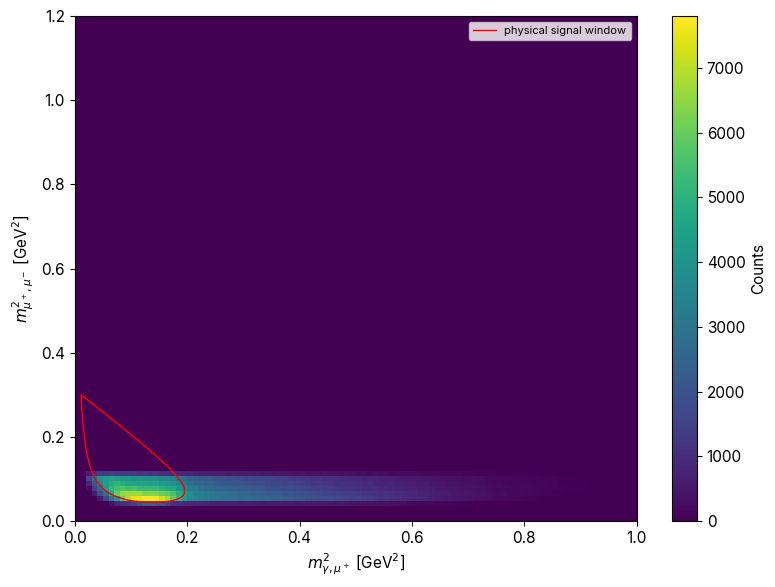

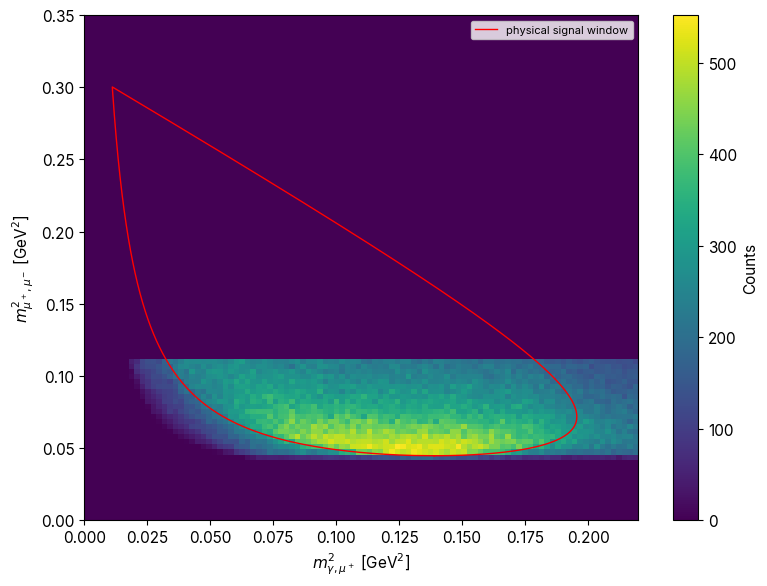

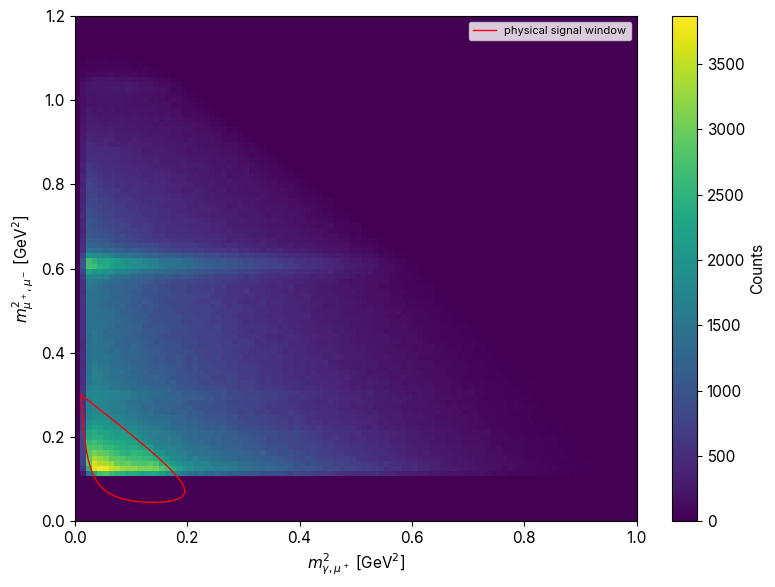

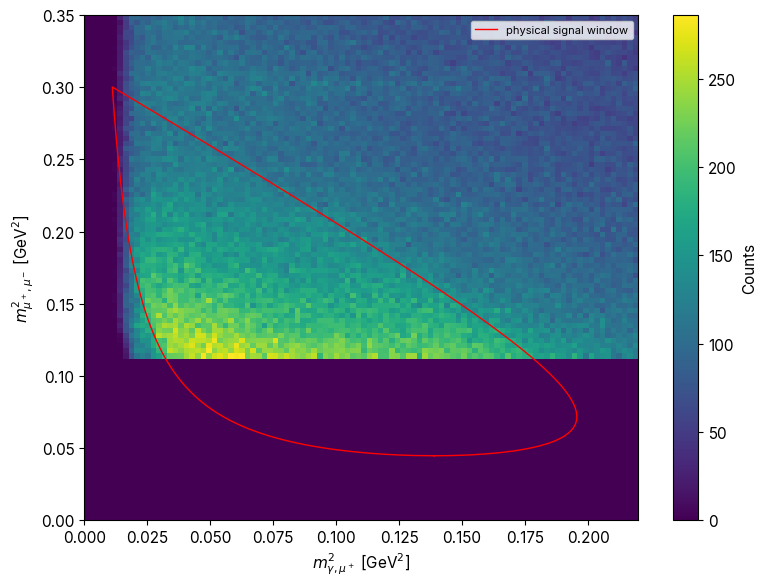

In [12]:
dalitz_font()
for name, sub in SUBSETS.items():
    plot_dalitz_hist(sub['m12s'], sub['m23s'], [[0, 1.0], [0, 1.2]],
                     '', os.path.join(sub['outdir'], 'dalitz_raw.png'))
    plot_dalitz_hist(sub['m12s'], sub['m23s'], [[0, 0.22], [0, 0.35]],
                     '', os.path.join(sub['outdir'], 'dalitz_raw_zoom.png'))

## Global mass fit

`fit_dcb()` on each q^2 subset's masses.

In [ ]:
tail_prior = None
if TAIL_PRIOR_PATH is not None:
    with open(TAIL_PRIOR_PATH, 'r') as f:
        m_mc = fit_utils.LoadedFit(json.load(f)['fit'])
    tail_prior = fit_utils.build_prior(m_mc, TAIL_PARAMS, factor=TAIL_PRIOR_FACTOR)

for name, sub in SUBSETS.items():
    result, m_global = fit_dcb(sub['masses'], xmin=XMIN, xmax=XMAX, nbins=MASS_NBINS,
                               mean_init=MEAN_INIT, sigma_init=SIGMA_INIT,
                               bkg_model=BKG_MODEL, tail_prior=tail_prior)
    result['meta']['tail_prior'] = (None if TAIL_PRIOR_PATH is None else
                                    {'path': TAIL_PRIOR_PATH, 'factor': TAIL_PRIOR_FACTOR})

    # Where the numbers came from -- the fit itself only ever saw an array.
    result['meta']['input_file'] = INFILE
    result['meta']['mass'] = 'rebuilt from daughters' if REBUILD_MASS else MASS_BRANCH
    result['meta']['selection'] = {
        # TOS on at least one line at every level, or None for no TOS cut.
        'tos': TOS_LINES if USE_TOS else None,
        'pnn_mu_min': PNN_MU_MIN,
        'best_candidate': f'min {METRIC_BRANCH}',
        'signal_daughters': SIGNAL_DAUGHTERS,
        'composition_asserted': True,
    }
    # Selection details, so the results file is self-contained. `events` and
    # `triggers` describe the shared read/cuts stage, upstream of the q^2 split.
    result['selection_report'] = {
        'events': drop_report,
        'triggers': tos_report,
        'cutflow': [{'cut': label, 'candidates': n} for label, n in cutflow],
        'best_candidate': {
            'metric': METRIC_BRANCH, 'method': 'min',
            'events_with_best_candidate': len(masses),
        },
        'branches_read': BRANCHES,
    }
    result['meta']['q2_split'] = {
        'variable': 'm23 = m^2(mu+, mu-)',
        'q2_max': Q2_MAX,
        'subset': name,
        'm23_range': [float(v) for v in sub['m23_range']],
    }

    sub['result'] = result
    sub['m_global'] = m_global

print(f'[INFO] global fit background model: {BKG_MODEL}')

In [14]:
# Debug: HESSE diagnostics per parameter, useful if the covariance check
# below fails.
for name, sub in SUBSETS.items():
    print(f"--- [{name}] {sub['label']} ---")
    print(sub['m_global'].fmin)
    for p in sub['m_global'].parameters:
        print(f"  {p:8s} value={sub['m_global'].values[p]:12.4f}  "
              f"error={sub['m_global'].errors[p]:10.4f}  limits={sub['m_global'].limits[p]}")

--- [below_q2max] q^2 < 0.112 GeV^2 ---
┌─────────────────────────────────────────────────────────────────────────┐
│                                Migrad                                   │
├──────────────────────────────────┬──────────────────────────────────────┤
│ FCN = 205.4 (χ²/ndof = 2.8)      │              Nfcn = 870              │
│ EDM = 1.49e-05 (Goal: 0.0002)    │                                      │
├──────────────────────────────────┼──────────────────────────────────────┤
│          Valid Minimum           │   Below EDM threshold (goal x 10)    │
├──────────────────────────────────┼──────────────────────────────────────┤
│      No parameters at limit      │           Below call limit           │
├──────────────────────────────────┼──────────────────────────────────────┤
│             Hesse ok             │         Covariance accurate          │
└──────────────────────────────────┴──────────────────────────────────────┘
  mean     value=    548.1814  error=    0.1050 

In [15]:
# Global fit's covariance for mean and sigma, loosened by SIGNAL_PRIOR_FACTOR
# (stdev multiplier), as a per-bin NormalConstraint below, preserving the
# mean-sigma correlation each subset's global fit measured. The background
# parameters get no prior (see SIGNAL_PRIOR_FACTOR in the config). BKG_MODEL
# is a fixed config choice, so BKG_MODEL_OBJ is shared by both subsets.
BKG_MODEL_OBJ = fit_utils.BACKGROUND_MODELS[BKG_MODEL]
PRIOR_PARAMS = ('mean', 'sigma')

for name, sub in SUBSETS.items():
    _, sub['cov_prior'] = fit_utils.build_prior(sub['m_global'], PRIOR_PARAMS,
                                                factor=SIGNAL_PRIOR_FACTOR)

[DONE] Plot saved to ../../out/eta2mumugamma/turbo/20260925_q2split/q2_below_0.112/global_gauss_fit.png.

────────────────────────────────────────────────
                Fit summary                 
────────────────────────────────────────────────
μ = 548.18 ± 0.10 MeV
σ = 17.77 ± 0.16 MeV
α_L = 1.43 ± 0.04, n_L = 2.8 ± 0.6
α_R = 1.02 ± 0.03, n_R = 3.49 ± 0.21
n_sig = 167164 ± 3724
n_bkg = 237980 ± 3733
c0 = 0.096 ± 0.009, c1 = 0.046 ± 0.011
χ²/ndof = 1.69
────────────────────────────────────────────────
[INFO][below_q2max] per-bin seeds: mean=548.181  sigma=17.769  bkg(cheb2): c0=0.096, c1=0.046
[INFO][below_q2max] per-bin fixed tails: alphaL=1.435  nL=2.759  alphaR=1.020  nR=3.493
[DONE] Plot saved to ../../out/eta2mumugamma/turbo/20260925_q2split/q2_above_0.112/global_gauss_fit.png.

────────────────────────────────────────────────
                Fit summary                 
────────────────────────────────────────────────
μ = 549.44 ± 0.15 MeV
σ = 22.26 ± 0.31 MeV
α_L = 0.93 ± 0.

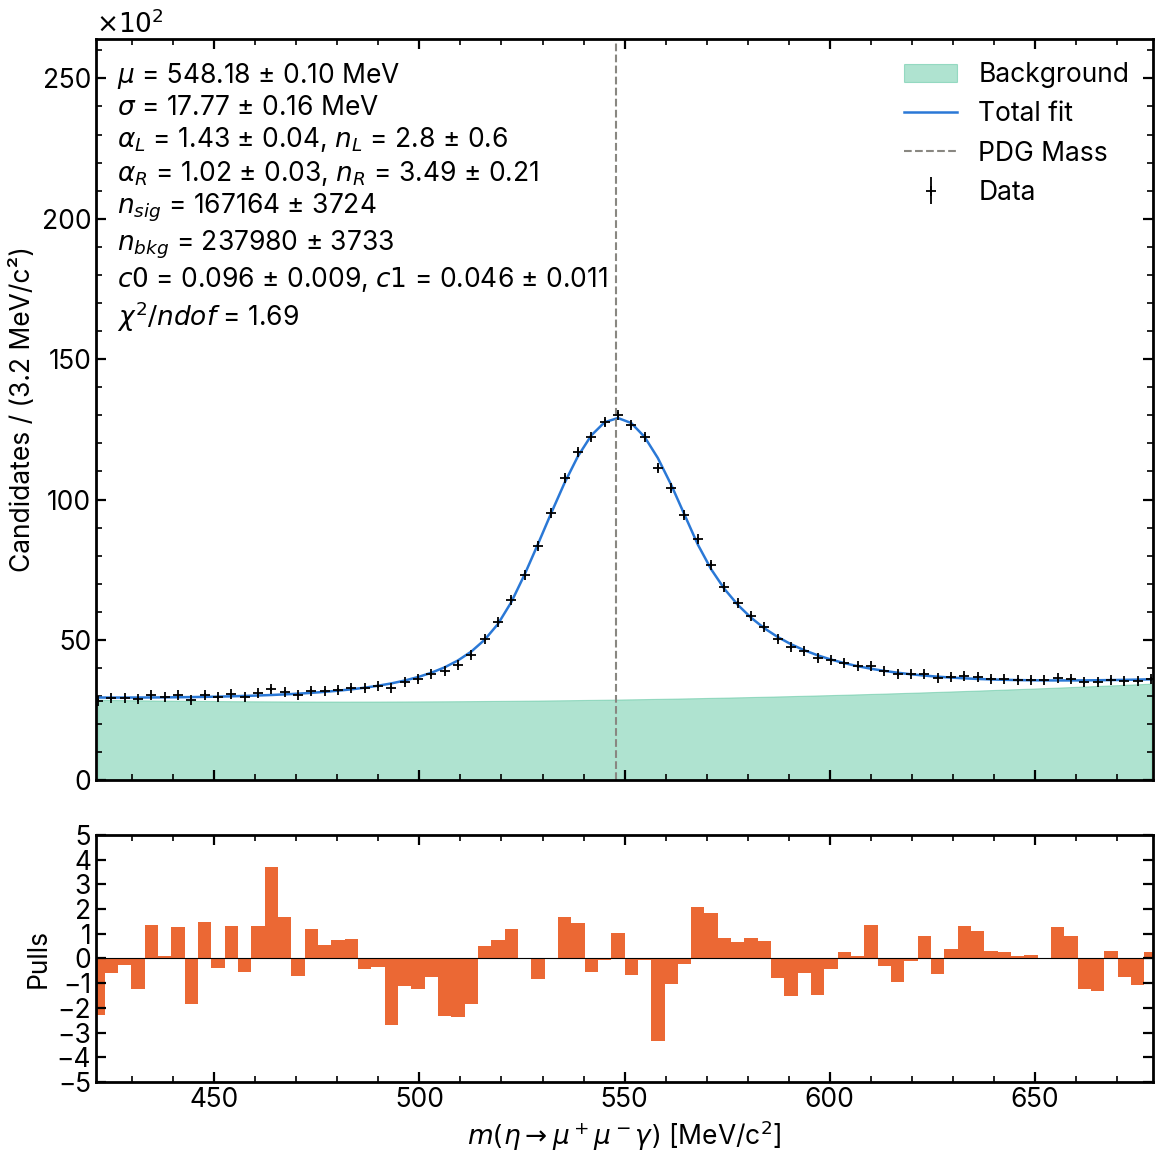

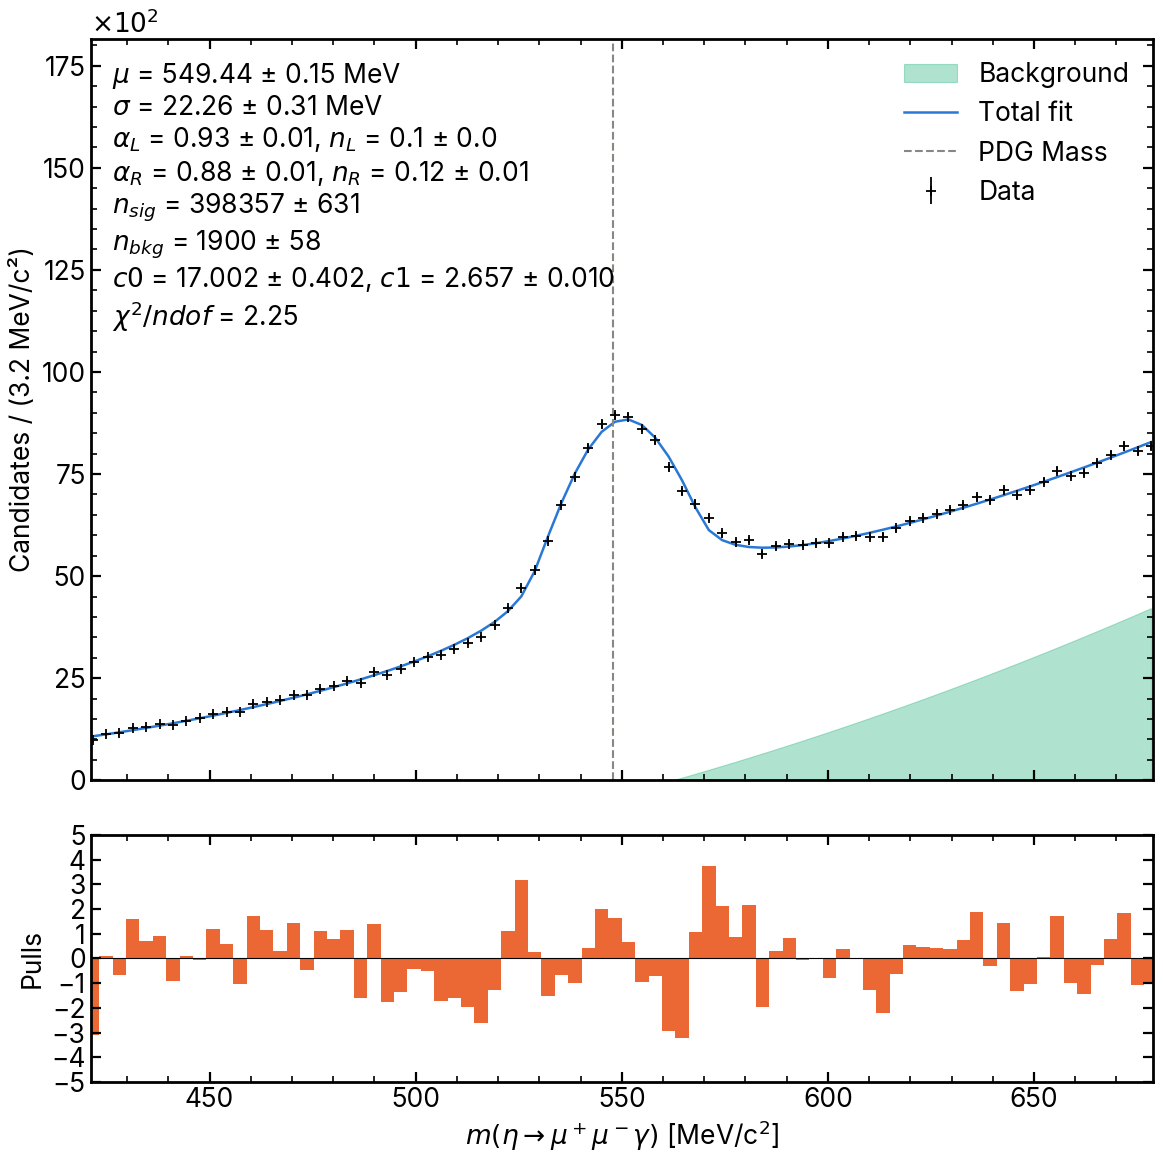

In [16]:
# Plot each subset's global fit result and store parameters for use in that
# subset's per-bin fits.
for name, sub in SUBSETS.items():
    plot_dcb(sub['result'], os.path.join(sub['outdir'], 'global_gauss_fit.png'))

    p = sub['result']['fit']['parameters']
    sub['mean_init']   = p['mean']['value']
    sub['sigma_init']  = p['sigma']['value']
    sub['alphaL_init'] = p['alphaL']['value']
    sub['nL_init']     = p['nL']['value']
    sub['alphaR_init'] = p['alphaR']['value']
    sub['nR_init']     = p['nR']['value']
    sub['bkg_init']    = {nm: p[nm]['value'] for nm in BKG_MODEL_OBJ.param_names}

    print(f"[INFO][{name}] per-bin seeds: mean={sub['mean_init']:.3f}  "
          f"sigma={sub['sigma_init']:.3f}  bkg({BKG_MODEL}): " +
          ', '.join(f'{k}={v:.3f}' for k, v in sub['bkg_init'].items()))
    print(f"[INFO][{name}] per-bin fixed tails: alphaL={sub['alphaL_init']:.3f}  "
          f"nL={sub['nL_init']:.3f}  alphaR={sub['alphaR_init']:.3f}  "
          f"nR={sub['nR_init']:.3f}")

## Per-Dalitz-bin fits

For each q^2 subset, using that subset's own rebinned m23 grid: the global
fit results seed the per-bin fits, with custom-tuned covariance/uncertainty
priors to help convergence.

In [17]:
# Mass histogram binning, shared by every per-bin fit AND every per-bin plot
# in both subsets -- the mass fit window doesn't depend on q^2.
MASS_EDGES = np.linspace(XMIN, XMAX, MASS_NBINS + 1)
MASS_CENTERS = 0.5 * (MASS_EDGES[:-1] + MASS_EDGES[1:])
MASS_BIN_WIDTH = (XMAX - XMIN) / MASS_NBINS

# m12 grid, shared by both subsets -- only the m23 (= q^2) axis is split.
n_per_dim = int(np.sqrt(DALITZ_NBINS))
m12_edges = np.linspace(*M12_RANGE, n_per_dim + 1)
for name, sub in SUBSETS.items():
    sub['m23_edges'] = np.linspace(*sub['m23_range'], n_per_dim + 1)


def dalitz_bin_mask(sub, i, j):
    """Half-open [lo, hi) mask selecting Dalitz bin (i, j) of this subset's grid."""
    m23_edges = sub['m23_edges']
    return ((sub['m12s'] >= m12_edges[i]) & (sub['m12s'] < m12_edges[i + 1]) &
            (sub['m23s'] >= m23_edges[j]) & (sub['m23s'] < m23_edges[j + 1]))


def bin_weight(sub, i, j):
    """Phase-space factor of Dalitz bin (i, j) of this subset's grid, as
    fit_utils's (xg, wg), or None if PHASE_SPACE is off."""
    if not PHASE_SPACE: return None
    m23_edges = sub['m23_edges']
    return fit_utils.make_weight(
        lambda M: kinematics.phase_space_factor(
            M, (m12_edges[i], m12_edges[i + 1]), (m23_edges[j], m23_edges[j + 1])),
        XMIN, XMAX)


def bin_shapes(weight):
    """(signal CDF, background model) for a bin, with the phase-space factor
    applied to both if `weight` is not None."""
    if weight is None:
        return fit_utils.dcb_cdf, BKG_MODEL_OBJ
    return (fit_utils.weighted_dcb_cdf(weight),
            fit_utils.weighted_bkg_model(BKG_MODEL_OBJ, weight))


def bin_prediction(fit_result, counts, weight):
    """Expected counts, data-based pulls and chi2/ndf for one bin's fit."""
    sig_cdf, model = bin_shapes(weight)
    p = fit_result.values
    n_sig, n_bkg = float(p['n_sig']), float(p['n_bkg'])
    bin_sig = np.diff(sig_cdf(MASS_EDGES, XMIN, XMAX, p['mean'], p['sigma'],
                              p['alphaL'], p['nL'], p['alphaR'], p['nR'])) * n_sig
    bin_bkg = np.diff(model.cdf(MASS_EDGES, XMIN, XMAX,
                                *(p[nm] for nm in model.param_names))) * n_bkg
    bin_fit = bin_sig + bin_bkg

    # Neyman (data-based) chi2/pulls: DATA is the variance estimate, so
    # sum(pulls**2) == chi2. Empty bins are skipped and don't count toward ndof.
    ok = counts > 0
    pulls = np.where(ok, (counts - bin_fit) / np.sqrt(np.where(ok, counts, 1.0)), 0.0)
    chi2 = float(np.sum((counts[ok] - bin_fit[ok])**2 / counts[ok]))
    ndof = int(ok.sum()) - fit_result.nfit
    return {
        'n_sig': n_sig, 'n_bkg': n_bkg,
        'bin_fit': bin_fit, 'bin_sig': bin_sig, 'bin_bkg': bin_bkg, 'pulls': pulls,
        'chi2': chi2, 'ndof': ndof,
        'chi2_per_ndof': chi2 / ndof if ndof > 0 else float('nan'),
    }

In [18]:
# Fit per Dalitz bin, per q^2 subset. Bins with too few candidates are skipped.
for name, sub in SUBSETS.items():
    fit_results = {}
    for i in range(n_per_dim):
        for j in range(n_per_dim):
            masses_in_bin = sub['masses'][dalitz_bin_mask(sub, i, j)]
            counts, edges = np.histogram(masses_in_bin, bins=MASS_EDGES)
            counts = counts.astype(float)
            n_cand = counts.sum()
            if n_cand <= MIN_CANDIDATES: continue

            # A bin the eta itself can't reach (f(m_eta) = 0) has no
            # physical signal, so n_sig is fixed to 0 there rather than
            # letting the DCB tails absorb background.
            weight = bin_weight(sub, i, j)
            no_signal = (weight is not None
                         and np.interp(kinematics.M_ETA, *weight) == 0.0)

            cost = fit_utils.make_dcb_cost(counts, edges, XMIN, XMAX, bkg=BKG_MODEL,
                                           weight=weight)
            cost = cost + NormalConstraint(PRIOR_PARAMS,
                                           (sub['mean_init'], sub['sigma_init']),
                                           error=sub['cov_prior'])
            init = dict(mean=sub['mean_init'], sigma=sub['sigma_init'],
                        alphaL=sub['alphaL_init'], nL=sub['nL_init'],
                        alphaR=sub['alphaR_init'], nR=sub['nR_init'],
                        n_sig=0.0 if no_signal else n_cand * 0.5,
                        n_bkg=n_cand if no_signal else n_cand * 0.5,
                        **(sub['bkg_init'] if weight is None else BKG_MODEL_OBJ.init))
            limits = dict(sigma=(0.0, None), alphaL=(0.0, None), alphaR=(0.0, None),
                          nL=(0.0, None), nR=(0.0, None),
                          n_sig=(0.0, None), n_bkg=(0.0, None),
                          **BKG_MODEL_OBJ.limits)
            # Tails fixed at the subset's global fit values -- too few
            # candidates per bin to float all 10 DCB params; only the core
            # and yields move.
            fixed = ['alphaL', 'nL', 'alphaR', 'nR']
            if no_signal:
                fixed += ['n_sig', 'mean', 'sigma']
            m = fit_utils.run_fit(cost, init, limits, fixed=fixed)

            fit_results[(i, j)] = {
                'fit': m,
                'n_cand': n_cand,
                'n_events': len(masses_in_bin),
                'weight': weight,
                'no_signal': no_signal,
                'm12_range': (m12_edges[i], m12_edges[i + 1]),
                'm23_range': (sub['m23_edges'][j], sub['m23_edges'][j + 1]),
            }
    sub['fit_results'] = fit_results

    # Yield maps. A bin never fit, or whose fit failed, stays 0.
    signal_counts = np.zeros((n_per_dim, n_per_dim))
    bkg_counts = np.zeros((n_per_dim, n_per_dim))
    for (i, j), r in fit_results.items():
        if not r['fit'].valid: continue
        signal_counts[i, j] = r['fit'].values['n_sig']
        bkg_counts[i, j] = r['fit'].values['n_bkg']
    sub['signal_counts'] = signal_counts
    sub['bkg_counts'] = bkg_counts

    print(f"[INFO][{name}] fitted {len(fit_results)} / {n_per_dim**2} Dalitz bins")

[INFO][below_q2max] fitted 109 / 196 Dalitz bins
[INFO][above_q2max] fitted 188 / 196 Dalitz bins


## Fit sanity checks

In [19]:
# A hole (yield = 0) is either too few candidates to attempt a fit, or a fit
# that ran and failed to converge.
for name, sub in SUBSETS.items():
    fit_results = sub['fit_results']
    skipped, invalid, valid = [], [], []
    for i in range(n_per_dim):
        for j in range(n_per_dim):
            if (i, j) not in fit_results:              skipped.append((i, j))
            elif not fit_results[(i, j)]['fit'].valid: invalid.append((i, j))
            else:                                      valid.append((i, j))
    sub['skipped'], sub['invalid'], sub['valid'] = skipped, invalid, valid

    print(f"--- [{name}] Per-bin fit outcome ({n_per_dim}x{n_per_dim} = "
          f"{n_per_dim**2} Dalitz bins) ---")
    print(f'  skipped (<= {MIN_CANDIDATES} raw candidates): {len(skipped)}')
    print(f'  fit invalid (hole):                {len(invalid)}')
    print(f'  fit valid:                         {len(valid)}')
    if invalid:
        print("  raw candidate counts at 'invalid fit' holes "
              "(large n_cand means the hole is a fit-convergence failure):")
        for (i, j) in invalid:
            print(f"    bin ({i:2d},{j:2d}): n_cand={fit_results[(i, j)]['n_cand']:8.0f}")

--- [below_q2max] Per-bin fit outcome (14x14 = 196 Dalitz bins) ---
  skipped (<= 10 raw candidates): 87
  fit invalid (hole):                0
  fit valid:                         109
--- [above_q2max] Per-bin fit outcome (14x14 = 196 Dalitz bins) ---
  skipped (<= 10 raw candidates): 8
  fit invalid (hole):                2
  fit valid:                         186
  raw candidate counts at 'invalid fit' holes (large n_cand means the hole is a fit-convergence failure):
    bin ( 5, 4): n_cand=    3036
    bin ( 6, 6): n_cand=    2230


In [20]:
# Background positivity check: the background shape floats per bin, and a fit
# can converge (valid == True) with the background curve dipping below zero
# somewhere in [XMIN, XMAX] -- a bogus nonzero yield the holes-only check
# above misses. With the phase-space factor on, only the region the bin can
# reach (f > 0) matters, and the check is on the raw (unfloored) Chebyshev.
x_check = np.linspace(XMIN, XMAX, 200)
for name, sub in SUBSETS.items():
    fit_results = sub['fit_results']
    neg_bkg_bins = []
    for (i, j) in sub['valid']:
        r = fit_results[(i, j)]['fit']
        weight = fit_results[(i, j)]['weight']
        reachable = np.ones_like(x_check, dtype=bool) if weight is None else \
            np.interp(x_check, *weight) > 0
        model = bin_shapes(weight)[1]
        shape = model.unnorm(x_check, XMIN, XMAX,
                             *(r.values[nm] for nm in BKG_MODEL_OBJ.param_names))
        if np.any(shape[reachable] < 0):
            neg_bkg_bins.append((i, j))
    sub['neg_bkg_bins'] = neg_bkg_bins

    print(f"--- [{name}] Background positivity check (valid fits only, "
          f"bkg_model={BKG_MODEL}) ---")
    print(f"{len(neg_bkg_bins)} / {len(sub['valid'])} valid fits have a background "
          f"curve that goes negative somewhere in [XMIN, XMAX].")
    for (i, j) in neg_bkg_bins[:10]:
        r = fit_results[(i, j)]['fit']
        vals = '  '.join(f'{nm}={r.values[nm]:.3f}' for nm in BKG_MODEL_OBJ.param_names)
        print(f'  ({i:2d},{j:2d}): {vals}')

--- [below_q2max] Background positivity check (valid fits only, bkg_model=cheb2) ---
11 / 109 valid fits have a background curve that goes negative somewhere in [XMIN, XMAX].
  ( 2, 7): c0=-1.515  c1=-0.883
  ( 2, 8): c0=-0.829  c1=-0.258
  ( 2,10): c0=-1.080  c1=0.059
  ( 2,12): c0=-1.537  c1=0.144
  ( 3, 6): c0=-1.106  c1=-0.488
  ( 3, 9): c0=-1.711  c1=-0.077
  ( 4, 7): c0=-1.647  c1=-0.172
  ( 5, 7): c0=-1.058  c1=0.028
  ( 6, 6): c0=-0.945  c1=-0.165
  ( 8, 5): c0=-0.590  c1=-0.489
--- [above_q2max] Background positivity check (valid fits only, bkg_model=cheb2) ---
82 / 186 valid fits have a background curve that goes negative somewhere in [XMIN, XMAX].
  ( 0, 2): c0=-5776.788  c1=-1837.534
  ( 0, 4): c0=1.545  c1=-0.109
  ( 0, 5): c0=1.779  c1=0.276
  ( 0, 6): c0=1.939  c1=0.258
  ( 0, 7): c0=2.149  c1=0.059
  ( 0, 8): c0=1.614  c1=0.202
  ( 0, 9): c0=1.554  c1=0.584
  ( 0,10): c0=2.379  c1=0.032
  ( 0,11): c0=2.776  c1=-0.267
  ( 0,12): c0=1.568  c1=0.076


In [21]:
# If a hole's raw n_cand is comparable to its immediate neighbors', the 0 in
# the yield map is a fit-convergence issue.
for name, sub in SUBSETS.items():
    fit_results = sub['fit_results']
    raw = np.full((n_per_dim, n_per_dim), np.nan)
    for (i, j), r in fit_results.items():
        raw[i, j] = r['n_cand']

    print(f'--- [{name}] Neighbor comparison for holes (raw n_cand) ---')
    if not sub['invalid']:
        print('No holes from non-convergence this run.')
    for (i, j) in sub['invalid']:
        neighbors = {(di, dj): raw[i + di, j + dj]
                     for di, dj in [(-1, 0), (1, 0), (0, -1), (0, 1)]
                     if 0 <= i + di < n_per_dim and 0 <= j + dj < n_per_dim
                     and not np.isnan(raw[i + di, j + dj])}
        if neighbors:
            neighbor_str = ', '.join(f'{k}: {v:.0f}' for k, v in neighbors.items())
            print(f'  hole ({i:2d},{j:2d}): n_cand={raw[i, j]:.0f}  '
                  f'neighbors: {neighbor_str}')

--- [below_q2max] Neighbor comparison for holes (raw n_cand) ---
No holes from non-convergence this run.
--- [above_q2max] Neighbor comparison for holes (raw n_cand) ---
  hole ( 5, 4): n_cand=3036  neighbors: (-1, 0): 3508, (1, 0): 2930, (0, -1): 3474, (0, 1): 2826
  hole ( 6, 6): n_cand=2230  neighbors: (-1, 0): 2474, (1, 0): 1753, (0, -1): 2539, (0, 1): 1812


In [22]:
# Per-bin yields should sum to roughly each subset's own global fit numbers,
# short by the out-of-grid fraction (within that subset's own m23 sub-range).
for name, sub in SUBSETS.items():
    n_sig_global = sub['result']['fit']['parameters']['n_sig']['value']
    n_bkg_global = sub['result']['fit']['parameters']['n_bkg']['value']
    m23_lo, m23_hi = sub['m23_range']
    in_grid = ((sub['m12s'] >= M12_RANGE[0]) & (sub['m12s'] < M12_RANGE[1]) &
               (sub['m23s'] >= m23_lo) & (sub['m23s'] < m23_hi))
    sub['in_grid'] = in_grid
    sub['n_sig_global'] = n_sig_global
    sub['n_bkg_global'] = n_bkg_global

    print(f'--- [{name}] Global vs summed per-bin yields ---')
    print(f"  candidates in the Dalitz grid : {int(in_grid.sum())} / {len(sub['masses'])}"
          f'  ({100 * in_grid.mean():.1f}%)')
    print(f"  n_sig  global {n_sig_global:10.1f}   summed {sub['signal_counts'].sum():10.1f}")
    print(f"  n_bkg  global {n_bkg_global:10.1f}   summed {sub['bkg_counts'].sum():10.1f}")

--- [below_q2max] Global vs summed per-bin yields ---
  candidates in the Dalitz grid : 453220 / 866891  (52.3%)
  n_sig  global   167163.6   summed   162445.8
  n_bkg  global   237979.9   summed   212754.2
--- [above_q2max] Global vs summed per-bin yields ---
  candidates in the Dalitz grid : 629946 / 2772885  (22.7%)
  n_sig  global   398356.9   summed   167432.2
  n_bkg  global     1899.5   summed   193709.3


## Fitted yield maps

Each subset's own Dalitz grid: signal and background yields per bin, rather
than raw candidate counts.

[DONE] Plot saved to ../../out/eta2mumugamma/turbo/20260925_q2split/q2_below_0.112/dalitz_signal_yield.png.
[DONE] Plot saved to ../../out/eta2mumugamma/turbo/20260925_q2split/q2_below_0.112/dalitz_bkg_yield.png.
[DONE] Plot saved to ../../out/eta2mumugamma/turbo/20260925_q2split/q2_above_0.112/dalitz_signal_yield.png.
[DONE] Plot saved to ../../out/eta2mumugamma/turbo/20260925_q2split/q2_above_0.112/dalitz_bkg_yield.png.


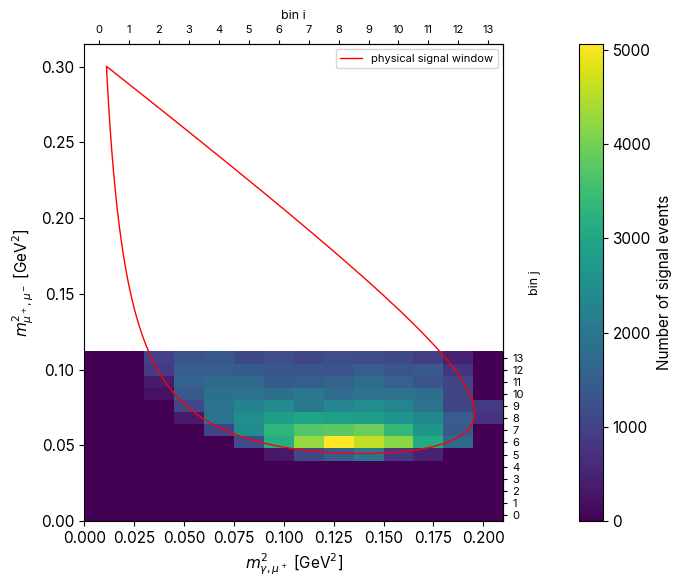

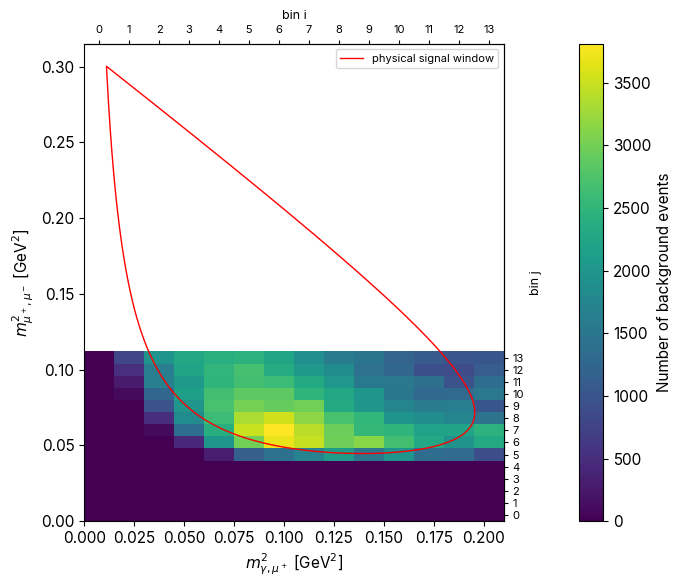

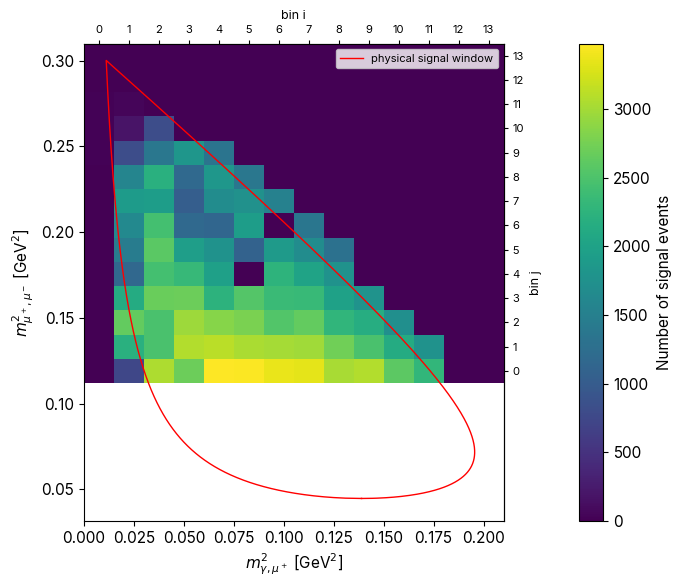

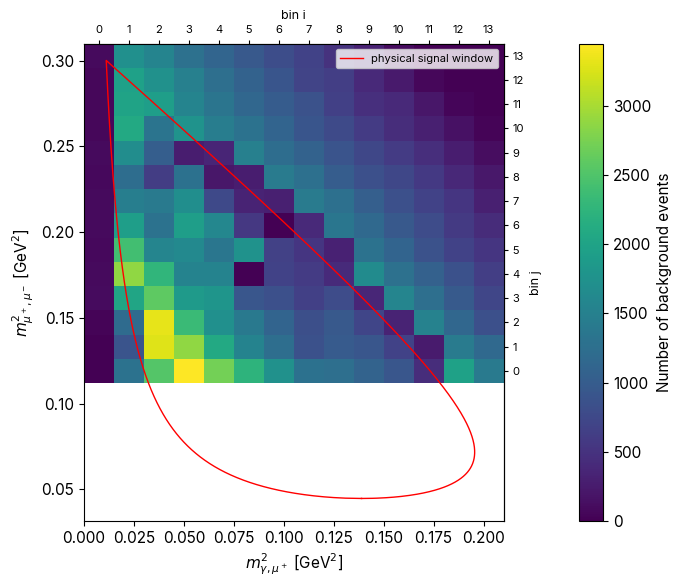

In [23]:
dalitz_font()
for name, sub in SUBSETS.items():
    plot_dalitz_map(sub['signal_counts'], 'Number of signal events', '',
                    os.path.join(sub['outdir'], 'dalitz_signal_yield.png'),
                    m12_edges, sub['m23_edges'])
    plot_dalitz_map(sub['bkg_counts'], 'Number of background events', '',
                    os.path.join(sub['outdir'], 'dalitz_bkg_yield.png'),
                    m12_edges, sub['m23_edges'])

## Results file

Each subset's global fit dict plus a `dalitz` section recording its own
per-bin outcome, written to that subset's own output directory.

In [24]:
for name, sub in SUBSETS.items():
    fit_results = sub['fit_results']
    bins = []
    for (i, j) in sorted(fit_results):
        r = fit_results[(i, j)]
        fit_result = r['fit']
        entry = {
            'i': i, 'j': j,
            'm12_range': [float(v) for v in r['m12_range']],
            'm23_range': [float(v) for v in r['m23_range']],
            'n_cand': float(r['n_cand']),
            'n_events': int(r['n_events']),
            'valid': bool(fit_result.valid),
            'n_sig_fixed_zero': bool(r['no_signal']),
        }
        if fit_result.valid:
            # Recount from the same mask the fit used, so chi2 here is the
            # chi2 of the histogram that was fit.
            counts, _ = np.histogram(sub['masses'][dalitz_bin_mask(sub, i, j)],
                                     bins=MASS_EDGES)
            pred = bin_prediction(fit_result, counts.astype(float), r['weight'])
            entry.update({
                'n_sig': round(pred['n_sig'], 2),
                'n_sig_err': round(float(fit_result.errors['n_sig']), 2),
                'n_bkg': round(pred['n_bkg'], 2),
                'n_bkg_err': round(float(fit_result.errors['n_bkg']), 2),
                **{nm: round(float(fit_result.values[nm]), 6)
                   for nm in BKG_MODEL_OBJ.param_names},
                'chi2': round(pred['chi2'], 4),
                'ndof': pred['ndof'],
                'chi2_per_ndof': round(pred['chi2_per_ndof'], 6),
                'bkg_goes_negative': (i, j) in sub['neg_bkg_bins'],
            })
        bins.append(entry)

    sub['result']['dalitz'] = {
        'm12_edges': m12_edges.tolist(),
        'm23_edges': sub['m23_edges'].tolist(),
        'nbins_total': n_per_dim**2,
        'nbins_per_dim': n_per_dim,
        'mass_window': {'xmin': XMIN, 'xmax': XMAX, 'nbins': MASS_NBINS},
        'min_candidates': MIN_CANDIDATES,
        'background_model': BKG_MODEL,
        'chi2_convention': 'neyman/data-based: sum (d - f)^2 / d',
        'pull_convention': 'data-based: (d - f) / sqrt(d)',
        'seeded_from_global_fit': list(PRIOR_PARAMS),
        'fixed_in_per_bin_fit': ['alphaL', 'nL', 'alphaR', 'nR'],
        'phase_space_factor': PHASE_SPACE,
        'phase_space_applied_to': ['signal', 'background'] if PHASE_SPACE else [],
        'mass': 'rebuilt from daughters' if REBUILD_MASS else MASS_BRANCH,
        'events_dropped_unphysical_m2': n_unphysical,
        'outcome': {'skipped': len(sub['skipped']), 'invalid': len(sub['invalid']),
                    'valid': len(sub['valid'])},
        'yield_closure': {
            'n_sig_global': sub['n_sig_global'],
            'n_sig_summed': float(sub['signal_counts'].sum()),
            'n_bkg_global': sub['n_bkg_global'],
            'n_bkg_summed': float(sub['bkg_counts'].sum()),
            'candidates_in_grid': int(sub['in_grid'].sum()),
            'candidates_total': len(sub['masses']),
        },
        'bins': bins,
    }

    # The fitted candidates' Dalitz variables and mass (in the grid and the
    # mass window), for downstream plots that need the events themselves.
    in_fit = (sub['in_grid'] & (sub['masses'] >= XMIN) & (sub['masses'] < XMAX))
    np.savez_compressed(os.path.join(sub['outdir'], 'dalitz_events.npz'),
                        m12s=sub['m12s'][in_fit].astype(np.float32),
                        m23s=sub['m23s'][in_fit].astype(np.float32),
                        masses=sub['masses'][in_fit].astype(np.float32),
                        m12_edges=m12_edges, m23_edges=sub['m23_edges'])

    json_path = os.path.join(sub['outdir'], 'dalitz_fit_results.json')
    with open(json_path, 'w') as f:
        json.dump(sub['result'], f, indent=2)
    print(f'[DONE][{name}] JSON saved to: {json_path}')

[DONE][below_q2max] JSON saved to: ../../out/eta2mumugamma/turbo/20260925_q2split/q2_below_0.112/dalitz_fit_results.json
[DONE][above_q2max] JSON saved to: ../../out/eta2mumugamma/turbo/20260925_q2split/q2_above_0.112/dalitz_fit_results.json


## Per-bin mass spectra

One page per Dalitz bin, including bins that were skipped or didn't
converge -- one PDF per q^2 subset.

In [25]:
# Stats-box text for a per-bin fit, in the same style as plot_dcb.build_text
# (mu, sigma, background params, n_sig, n_bkg, chi2/ndof) with the tail
# params omitted -- they're fixed per bin, so they'd show a meaningless
# zero error -- and n_cand folded into the extra line.
SIGNAL_KEYS = {'mean', 'sigma', 'n_sig', 'n_bkg'}

def make_build_text(n_cand):
    def build_text(params, chi2_per_ndof):
        mean, mean_err   = plot_utils.val_err(params['mean'])
        sigma, sigma_err = plot_utils.val_err(params['sigma'])
        n_sig, n_sig_err = plot_utils.val_err(params['n_sig'])
        n_bkg, n_bkg_err = plot_utils.val_err(params['n_bkg'])

        bkg_row = [(nm, nm, *plot_utils.val_err(params[nm]), '.3f', '')
                   for nm in params if nm not in SIGNAL_KEYS]

        stats = [
            [(r'\mu', 'μ', mean, mean_err, '.2f', 'MeV')],
            [(r'\sigma', 'σ', sigma, sigma_err, '.2f', 'MeV')],
            [(r'n_{sig}', 'n_sig', n_sig, n_sig_err, '.0f', '')],
            [(r'n_{bkg}', 'n_bkg', n_bkg, n_bkg_err, '.0f', '')],
            bkg_row,
        ]
        extra = (
            f'$n_{{cand}}$ = {n_cand:.0f}\n$\\chi^2/ndof$ = {chi2_per_ndof:.2f}',
            f'n_cand = {n_cand:.0f}\nχ²/ndof = {chi2_per_ndof:.2f}',
        )
        return plot_style.build_stats_text(stats, extra=extra)
    return build_text

In [26]:
dalitz_font()
for name, sub in SUBSETS.items():
    fit_results = sub['fit_results']
    m23_edges = sub['m23_edges']
    pdf_path = os.path.join(sub['outdir'], 'per_bin_fits.pdf')
    n_pages = n_fitted = 0

    with PdfPages(pdf_path) as pdf:
        for i in range(n_per_dim):
            for j in range(n_per_dim):
                # Same mask the fit used, so the page shows the same candidates.
                mask = dalitz_bin_mask(sub, i, j)
                counts = np.histogram(sub['masses'][mask], bins=MASS_EDGES)[0].astype(float)
                # .get() -> None for bins that were never fit at all.
                r = fit_results.get((i, j))
                fit_result = r['fit'] if r is not None else None
                has_fit = fit_result is not None and fit_result.valid

                title = (f'Bin ({i}, {j}): '
                         f'm12=[{m12_edges[i]:.4f}, {m12_edges[i + 1]:.4f}], '
                         f'm23=[{m23_edges[j]:.4f}, {m23_edges[j + 1]:.4f}]')

                if has_fit:
                    p = fit_result.values
                    pred = bin_prediction(fit_result, counts, r['weight'])

                    params = {
                        'mean': {'value': float(p['mean']), 'error': float(fit_result.errors['mean'])},
                        'sigma': {'value': float(p['sigma']), 'error': float(fit_result.errors['sigma'])},
                        'n_sig': {'value': pred['n_sig'], 'error': float(fit_result.errors['n_sig'])},
                        'n_bkg': {'value': pred['n_bkg'], 'error': float(fit_result.errors['n_bkg'])},
                        **{nm: {'value': float(p[nm]), 'error': float(fit_result.errors[nm])}
                           for nm in BKG_MODEL_OBJ.param_names},
                    }
                    data = {
                        'meta': {'input_file': INFILE},
                        **({'phase_space': {'x': r['weight'][0], 'f': r['weight'][1]}}
                           if r['weight'] is not None else {}),
                        'fit': {'parameters': params, 'chi2_per_ndof': pred['chi2_per_ndof']},
                        'histogram': {
                            'bin_centers': MASS_CENTERS,
                            'bin_counts': counts,
                            'bin_errors': np.sqrt(counts),
                            'bin_fit': pred['bin_fit'],
                            'bin_sig': pred['bin_sig'],
                            'bin_bkg': pred['bin_bkg'],
                            'bin_pulls': pred['pulls'],
                        },
                    }
                    fig, ax, ax_pull, _, _ = build_fit_figure(
                        data, make_build_text(r['n_cand']), x_lim=(XMIN, XMAX), title=title)
                else:
                    # No fit to draw -- data-only page, styled identically to
                    # the fitted pages (font, figure size, colors, ticks/spines,
                    # legend, labels) except for the fit-specific elements
                    # (curves, stats box) which don't exist here.
                    plot_utils.apply_font()
                    plt.rcParams['font.size'] = 19
                    fig, (ax, ax_pull) = plt.subplots(
                        2, 1, figsize=(12, 12), sharex=True,
                        gridspec_kw={'height_ratios': [3, 1]})
                    ax.set_title(title)
                    ax.set_xlim(XMIN, XMAX)
                    ax.errorbar(MASS_CENTERS, counts, yerr=np.sqrt(counts), fmt='+',
                                color=plot_style.COLORS['data'], markersize=7,
                                markeredgewidth=1.3, elinewidth=1.3, capsize=0,
                                label='Data')
                    ax.axvline(x=547.86, color=plot_style.COLORS['reference'],
                               linestyle='--', label='PDG Mass')
                    plot_style.style_axes(ax)
                    legend = ax.legend(loc='upper right', frameon=True, fancybox=False,
                                        edgecolor='none', framealpha=1)
                    ax.set_ylabel(f'Candidates / ({MASS_BIN_WIDTH:.1f} MeV/c²)')

                    if r is None:
                        status = (f'NO FIT ATTEMPTED\n{int(mask.sum())} candidates '
                                  f'(threshold is {MIN_CANDIDATES})')
                    else:
                        status = f"FIT DID NOT CONVERGE\nn_cand = {r['n_cand']:.0f}"
                    status_box = ax.text(
                        0.02, 0.97, status, transform=ax.transAxes, va='top',
                        ha='left', family='monospace', color='red',
                        bbox=dict(boxstyle='round,pad=0.4', facecolor='none', edgecolor='none'))

                    content_max = max(float(counts.max()) if counts.size else 0.0, 1.0)
                    plot_style.reserve_top_margin(ax, content_max, artists=[status_box, legend])
                    plot_style.format_y_axis(ax)

                    ax_pull.text(0.5, 0.5, 'no fit', transform=ax_pull.transAxes,
                                 ha='center', va='center', color='gray', fontsize=9)
                    ax_pull.axhline(0, color=plot_style.COLORS['data'], lw=0.8)
                    ax_pull.set_ylim(-5, 5)
                    plot_style.style_axes(ax_pull, minor_y=False)
                    ax_pull.set_ylabel('Pulls')
                    ax_pull.set_xlabel(plot_style.decay_label({'input_file': INFILE}))

                fig.tight_layout()
                pdf.savefig(fig)
                plt.close(fig)
                n_pages += 1
                n_fitted += int(has_fit)

    print(f'[DONE][{name}] wrote {n_pages} pages to {pdf_path} '
          f'({n_fitted} with a fit, {n_pages - n_fitted} data-only)')

[DONE][below_q2max] wrote 196 pages to ../../out/eta2mumugamma/turbo/20260925_q2split/q2_below_0.112/per_bin_fits.pdf (109 with a fit, 87 data-only)
[DONE][above_q2max] wrote 196 pages to ../../out/eta2mumugamma/turbo/20260925_q2split/q2_above_0.112/per_bin_fits.pdf (186 with a fit, 10 data-only)
